# Lattice construction

In [1]:
lattice_name   = 'v02_04_01_01'
description    = 'LGB lattice starting from v02_03_01_01, with larger slices, better MCF and a D1 angle of 1.3 deg.'
finalized_date = '261124'

In [16]:
# Standard imports
import numpy as np
import scipy
import matplotlib.pyplot as plt
from scipy.optimize import minimize, NonlinearConstraint, approx_fprime

import pickle
import os
from copy import deepcopy

import at

import utils as u

from importlib import reload
reload(u.at);
reload(u.plot);
reload(u.optimize);

## Load ring

In [4]:
with open('candidates/v02_03_01_01/ring.pkl', 'rb') as file:
    ring0 = pickle.load(file)

TDR_1 = u.at.TDR_1


## Decrease the number of slices

In [5]:
ring = deepcopy(ring0)
len(ring['D1_v2'])//2
len(ring['D2_v2'])//10

# Get original magnet strengths
D1_angle = [e.BendingAngle for e in ring['D1_v2'][0:10]]
D2_angle = [e.BendingAngle for e in ring['D2_v2'][0:10]]

D1_K = [e.K for e in ring['D1_v2'][0:10]]
D2_K = [e.K for e in ring['D2_v2'][0:10]]

# Redistribute angle, K and length
for name in ['D1_v2', 'D2_v2']:
    for i in range(0, 10, 2):
        D_0 = ring[name][i]
        D_1 = ring[name][i+1]

        D_0.K = 0.5*(D_0.K + D_1.K)
        D_0.BendingAngle = D_0.BendingAngle + D_1.BendingAngle
        D_0.Length = D_0.Length + D_1.Length
        D_1.Remove = True # Mark for removal

# Remove marked slices
for i in range(len(ring) - 1, -1, -1):
    if getattr(ring[i], "Remove", False):
        ring.remove(ring[i])


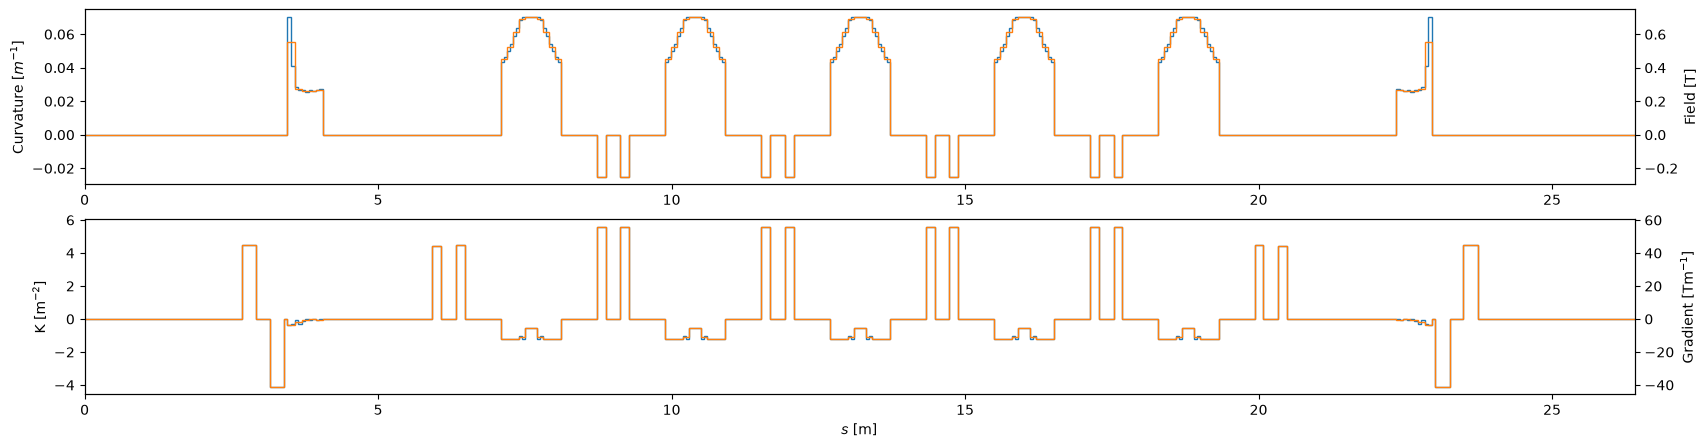

/gpfs/offline1/staff/common/alfpet/git/lattice_design/.venv/lib64/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,


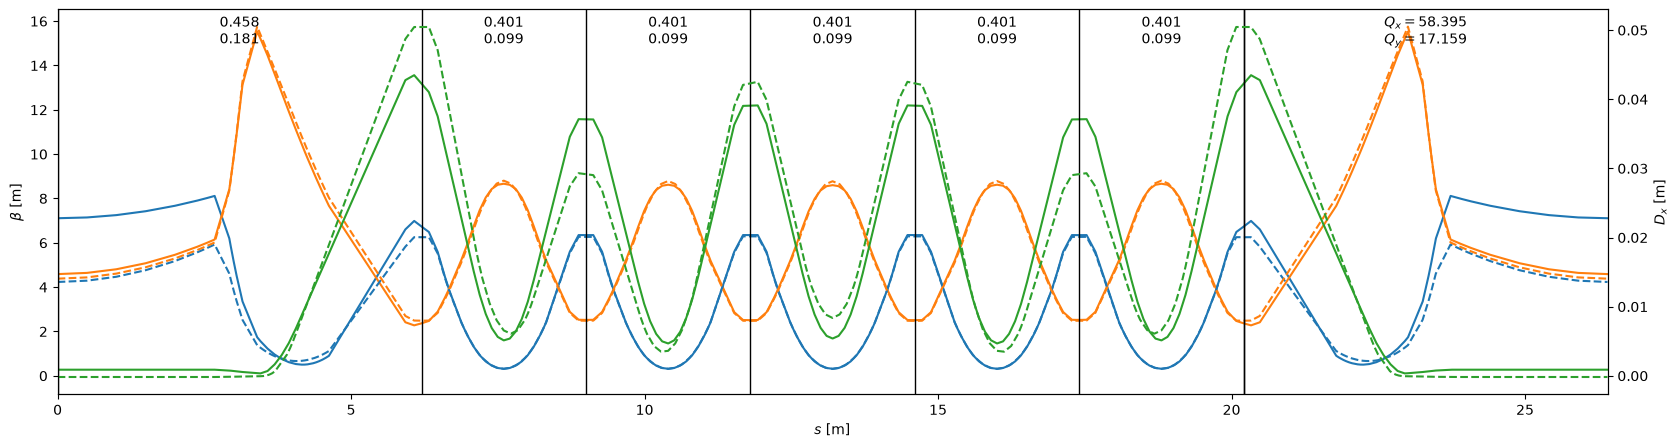

Emittance                  : 51.8 pm.rad
Tunes                      : [58.395, 17.159]
Momentum compaction        : 5.04e-05 d +3.73e-04 d^2 -6.54e-04 d^3
D1 angle                   : 1.125 degrees
Crotch absorber separation : 30.62 mm


In [6]:
fig, axs = plt.subplots(2, 1, figsize=(20, 5))
u.plot.plot_magnet(ring0, axs)
u.plot.plot_magnet(ring, axs)
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(20, 5))
u.plot.linear(ring, ax=ax)
plt.show()

u.at.summary(ring)

## Optimization

In [18]:
ring_opt = deepcopy(ring)
index_rho = u.optimize.get_index(ring, ["D1_v2", "R1_v2", "D2_v2", "R2_v2"])
index_K = u.optimize.get_index(ring, ["Q1_v2", "Q2_v2", "D1_v2", "Q3_v2", "R1_v2", "D2_v2", "R2_v2"]) 

# Zero quadrupoles in D1 (to change to positive K)
for e in ring_opt['D1_v2']: e.K = 0

tunes = np.array([58.399, 17.168])
tunes_tol = 1e-3

UC_tunes_target = np.array([0.4, 0.1])
UC_tunes_tol = 1e-3

constraints = [
    u.optimize.ID_constraints(ring_opt, index_rho, index_K),
    u.optimize.UC_constraints(ring_opt, index_rho, index_K),
    u.optimize.tune_constraints(ring_opt, index_rho, index_K, lb=tunes - tunes_tol, ub=tunes + tunes_tol),
    u.optimize.mcf_constraints(ring_opt, index_rho, index_K, lb=5.3e-5),
    u.optimize.D1_constraints(ring_opt, index_rho, index_K, lb=1.3,),
]

bounds = u.optimize.get_bounds(
    ring, index_rho, index_K,
    D1=(0, 0.07, 0, 1.2), # Changed to positive K
    D2=(0, 0.07, -1.2, 0),
    R1=(-0.025, 0.025, -6, 6), # Let R1 be a positive bend
    R2=(-0.025, 0, -6, 6),
    Q1=(None, None, -6, 6),
    Q2=(None, None, -6, 6),
    Q3=(None, None, -6, 6),
)

# Use trust-constr for initial few iterations to gently satisfy the constraints
result = scipy.optimize.minimize(
    method='trust-constr',
    fun=u.optimize.emittance,
    x0=u.optimize.get_x(ring_opt, index_rho, index_K),
    args=(ring_opt, index_rho, index_K),
    constraints=constraints,
    bounds=bounds,
    callback=u.optimize.callback,
    options=dict(maxiter=30),
)

# Second optimization using SLSQP
result = scipy.optimize.minimize(
    method='SLSQP',
    fun=u.optimize.emittance,
    x0=u.optimize.get_x(ring_opt, index_rho, index_K),
    args=(ring_opt, index_rho, index_K),
    constraints=constraints,
    bounds=bounds,
    callback=u.optimize.callback,
)
result

Running...
 fun: 68.13297007200336
   x: [ 2.025e-01  7.000e-02 ... -4.315e-01  5.539e+00]


     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 53.47231430811029
           x: [ 2.026e-01  5.687e-02 ... -4.312e-01  5.539e+00]
         nit: 28
         jac: [ 4.737e+02  1.983e+03 ...  5.138e+00 -1.737e+02]
        nfev: 811
        njev: 27
 multipliers: [-8.310e-01 -3.366e+02 ...  1.932e+05  3.862e+01]

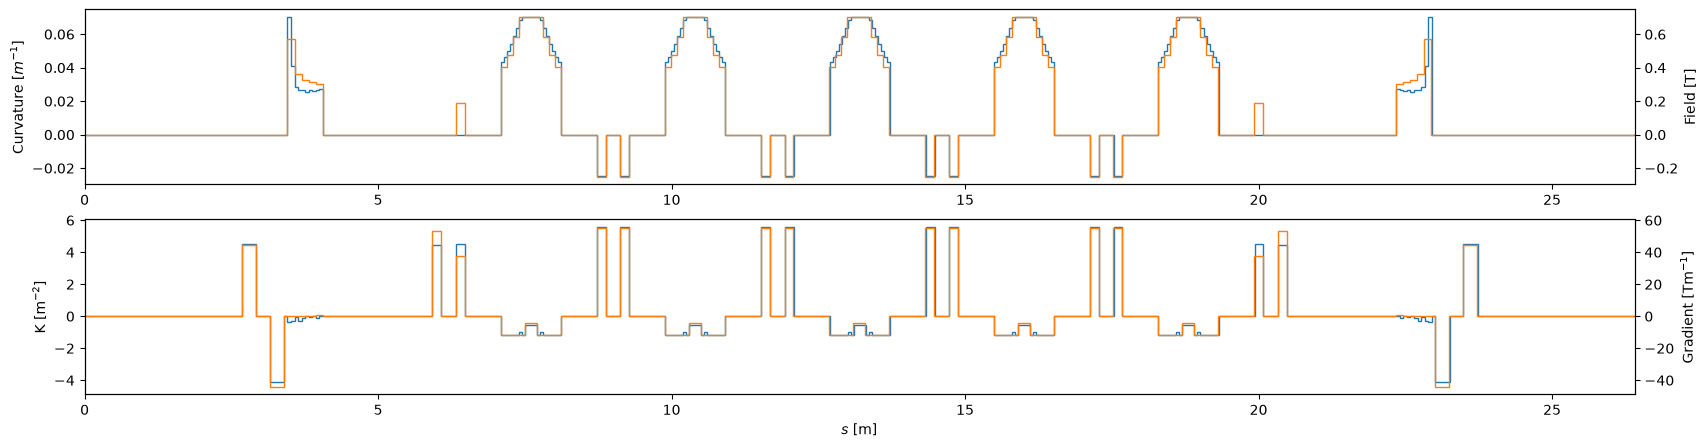

/gpfs/offline1/staff/common/alfpet/git/lattice_design/.venv/lib64/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,


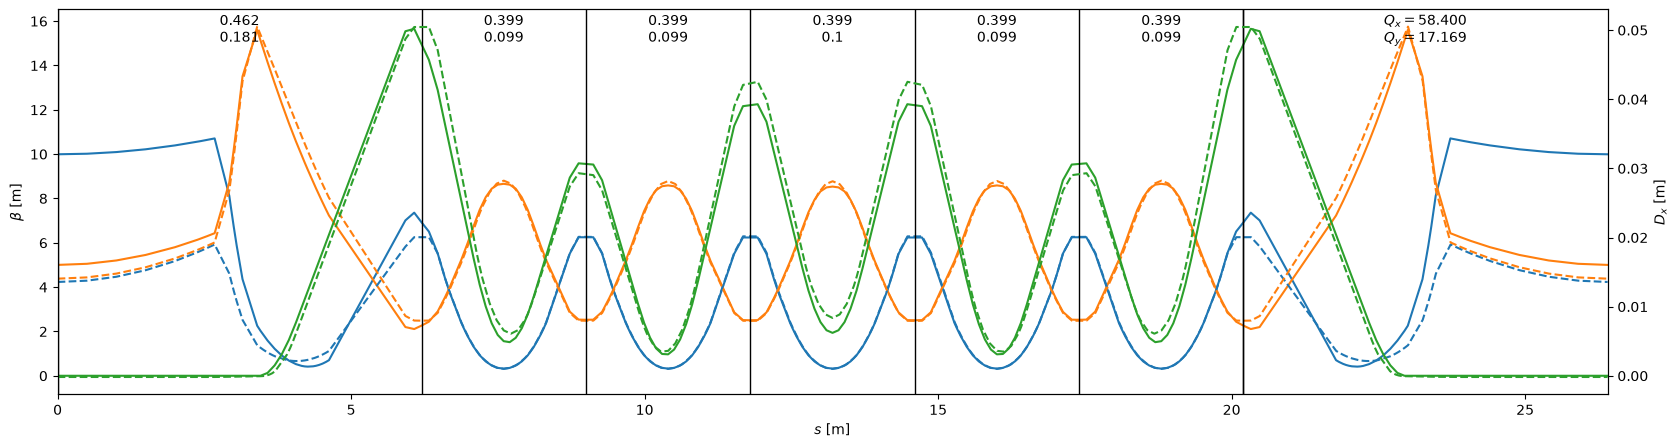

Emittance                  : 53.5 pm.rad
Tunes                      : [58.400, 17.169]
Momentum compaction        : 5.30e-05 d +3.72e-04 d^2 -6.41e-04 d^3
D1 angle                   : 1.300 degrees
Crotch absorber separation : 35.23 mm


In [19]:
fig, axs = plt.subplots(2, 1, figsize=(20, 5))
u.plot.plot_magnet(ring0, axs)
u.plot.plot_magnet(ring_opt, axs)
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(20, 5))
u.plot.linear(ring_opt, ax=ax)
plt.show()

u.at.summary(ring_opt)

## Save lattice

In [20]:
try:
    os.mkdir(f'candidates/{lattice_name}')
except FileExistsError:
    pass
    
with open(f'candidates/{lattice_name}/ring.pkl', 'wb') as file:
    pickle.dump(ring_opt, file)

at.save_mat(ring_opt, f'candidates/{lattice_name}/achro.mat')